In [41]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import re
from IPython.display import display

print("Libraries imported successfully")

Libraries imported successfully


In [16]:
# CFG for Balanced Parentheses

balanced_rules = {
    "S": ["( S ) S", "ε"]
}

balanced_cfg_table = pd.DataFrame(
    [(key, " | ".join(value))
     for key, value in balanced_rules.items()],
    columns=["Non-Terminal", "Production Rules"]
)

display(balanced_cfg_table)

,Non-Terminal,Production Rules
0,S,( S ) S | ε


In [17]:
# PDA Transitions for Balanced Parentheses

pda_transitions = [
    ["q0", "ε", "Z0", "S Z0", "q1"],
    ["q1", "ε", "S", "( S ) S", "q1"],
    ["q1", "ε", "S", "ε", "q1"],
    ["q1", "(", "(", "ε", "q1"],
    ["q1", ")", ")", "ε", "q1"],
    ["q1", "ε", "Z0", "ε", "qf"]
]

pda_table = pd.DataFrame(
    pda_transitions,
    columns=[
        "Current State",
        "Input",
        "Stack Top",
        "Stack Replacement",
        "Next State"
    ]
)

display(pda_table)

,Current State,Input,Stack Top,Stack Replacement,Next State
0,q0,ε,Z0,S Z0,q1
1,q1,ε,S,( S ) S,q1
2,q1,ε,S,ε,q1
3,q1,(,(,ε,q1
4,q1,),),ε,q1
5,q1,ε,Z0,ε,qf


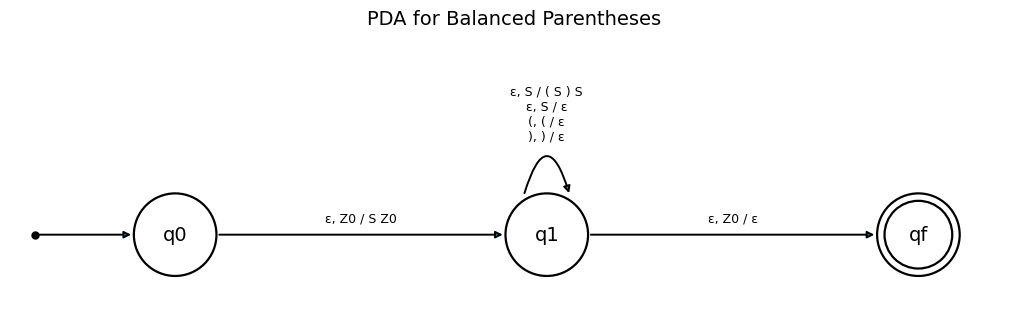

In [46]:
# PDA State Diagram for Balanced Parentheses
# NOTE: draw_pda() is defined here and reused by cells 12 and 21, so run this cell first.

from matplotlib.patches import Circle

def draw_pda(title, nodes, edges, width=13, height=5):
    """
    nodes : {name: (x_position, is_final_state)}
    edges : (source, destination, label)  or  (source, destination, label, "below")
            source == destination draws a self-loop above the state.
    """
    r = 0.5
    max_lines = max(e[2].count("\n") + 1 for e in edges if e[0] == e[1])
    top = r + 0.75 + 0.30 * max_lines
    below_lines = [e[2].count("\n") + 1 for e in edges if len(e) > 3 and e[3] == "below"]
    bottom = -0.9 - 0.30 * (max(below_lines) if below_lines else 0)

    fig, ax = plt.subplots(figsize=(width, height))

    for name, (x, final) in nodes.items():
        ax.add_patch(Circle((x, 0), r, fill=False, lw=1.6))
        if final:
            ax.add_patch(Circle((x, 0), r - 0.09, fill=False, lw=1.6))
        ax.text(x, 0, name, ha="center", va="center", fontsize=14)

    # start arrow
    first = list(nodes.values())[0][0]
    ax.plot(first - 1.7, 0, "ko", markersize=5)
    ax.annotate("", xy=(first - r, 0), xytext=(first - 1.7, 0),
                arrowprops=dict(arrowstyle="-|>", lw=1.4))

    for edge in edges:
        src, dst, label = edge[0], edge[1], edge[2]
        below = len(edge) > 3 and edge[3] == "below"
        xs, xd = nodes[src][0], nodes[dst][0]

        if src == dst:                               # self-loop
            ax.annotate("", xy=(xs + 0.28, r - 0.03), xytext=(xs - 0.28, r - 0.03),
                        arrowprops=dict(arrowstyle="-|>", lw=1.4,
                                        connectionstyle="arc3,rad=-1.7"))
            ax.text(xs, r + 0.62, label, ha="center", va="bottom", fontsize=9)
        else:                                        # normal edge
            ax.annotate("", xy=(xd - r, 0), xytext=(xs + r, 0),
                        arrowprops=dict(arrowstyle="-|>", lw=1.4))
            mid = (xs + xd) / 2
            if below:
                ax.text(mid, -0.15, label, ha="center", va="top", fontsize=9)
            else:
                ax.text(mid, 0.12, label, ha="center", va="bottom", fontsize=9)

    last = max(v[0] for v in nodes.values())
    ax.set_xlim(first - 2.0, last + 1.2)
    ax.set_ylim(bottom, top)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=14)
    plt.show()


draw_pda(
    "PDA for Balanced Parentheses",
    nodes={"q0": (2.0, False), "q1": (6.5, False), "qf": (11.0, True)},
    edges=[
        ("q0", "q1", "ε, Z0 / S Z0"),
        ("q1", "q1", "ε, S / ( S ) S\nε, S / ε\n(, ( / ε\n), ) / ε"),
        ("q1", "qf", "ε, Z0 / ε"),
    ]
)

In [19]:
# Function to validate balanced parentheses

def validate_parentheses(expression):
    stack = []

    for char in expression:
        if char == "(":
            stack.append(char)

        elif char == ")":
            if len(stack) == 0:
                return False
            stack.pop()

        else:
            return False

    return len(stack) == 0


print("Balanced Parentheses Validator is ready")

Balanced Parentheses Validator is ready


In [20]:
# Test cases for balanced parentheses

test_cases = [
    "()",
    "(())",
    "()()",
    "((()))",
    "",
    "(",
    ")",
    "(()",
    "())",
    "(()))",
    "(a)"
]

results = []

for expression in test_cases:
    if validate_parentheses(expression):
        results.append([expression, "Accepted"])
    else:
        results.append([expression, "Rejected"])

test_table = pd.DataFrame(
    results,
    columns=["Input String", "Result"]
)

display(test_table)

,Input String,Result
0,(),Accepted
1,(()),Accepted
2,()(),Accepted
3,((())),Accepted
4,,Accepted
5,(,Rejected
6,),Rejected
7,((),Rejected
8,()),Rejected
9,(())),Rejected


In [21]:
# Derivation for the string ()()

derivation_steps = [
    ["S", "Start"],
    ["( S ) S", "Apply S → ( S ) S"],
    ["( ε ) S", "Apply S → ε"],
    ["() S", "Remove ε"],
    ["() ( S ) S", "Apply S → ( S ) S"],
    ["() ( ε ) S", "Apply S → ε"],
    ["()() S", "Remove ε"],
    ["()()", "Apply S → ε"]
]

derivation_table = pd.DataFrame(
    derivation_steps,
    columns=["Derivation Step", "Production Applied"]
)

display(derivation_table)

,Derivation Step,Production Applied
0,S,Start
1,( S ) S,Apply S → ( S ) S
2,( ε ) S,Apply S → ε
3,() S,Remove ε
4,() ( S ) S,Apply S → ( S ) S
5,() ( ε ) S,Apply S → ε
6,()() S,Remove ε
7,()(),Apply S → ε


In [22]:
# Unsuccessful Derivations for Balanced Parentheses

failed_cases = [
    ["(()", "Missing closing parenthesis"],
    ["())", "Extra closing parenthesis"],
    [")(", "Incorrect order of parentheses"],
    ["((()", "Unclosed parentheses"],
    ["(()))", "Extra closing parenthesis"]
]

failed_table = pd.DataFrame(
    failed_cases,
    columns=["Input String", "Reason for Rejection"]
)

display(failed_table)

,Input String,Reason for Rejection
0,((),Missing closing parenthesis
1,()),Extra closing parenthesis
2,)(,Incorrect order of parentheses
3,(((),Unclosed parentheses
4,(())),Extra closing parenthesis


In [23]:
# Testing Summary for Balanced Parentheses

total = len(test_cases)

accepted = sum(
    validate_parentheses(expression)
    for expression in test_cases
)

rejected = total - accepted

summary = pd.DataFrame({
    "Category": ["Total Test Cases", "Accepted", "Rejected"],
    "Count": [total, accepted, rejected]
})

display(summary)

print("Balanced Parentheses Testing Completed Successfully")

,Category,Count
0,Total Test Cases,11
1,Accepted,5
2,Rejected,6


Balanced Parentheses Testing Completed Successfully


In [24]:
# CFG for Arithmetic Expression Validation

arithmetic_rules = {
    "E": ["T A"],
    "A": ["+ T A", "- T A", "ε"],
    "T": ["F B"],
    "B": ["* F B", "/ F B", "ε"],
    "F": ["( E )", "id", "num"]
}

arithmetic_cfg_table = pd.DataFrame(
    [(key, " | ".join(value))
     for key, value in arithmetic_rules.items()],
    columns=["Non-Terminal", "Production Rules"]
)

display(arithmetic_cfg_table)

,Non-Terminal,Production Rules
0,E,T A
1,A,+ T A | - T A | ε
2,T,F B
3,B,* F B | / F B | ε
4,F,( E ) | id | num


In [47]:
# PDA transitions for arithmetic expressions
# Format: [current state, input, stack top, stack replacement, next state]
# The replacement is written top-of-stack first.  Every terminal has its own matching row.

arithmetic_transitions = [
    ["q0", "ε", "Z0", "E Z0", "q1"],

    # expand variables (ε-moves)
    ["q1", "ε", "E", "T A",    "q1"],
    ["q1", "ε", "A", "+ T A",  "q1"],
    ["q1", "ε", "A", "- T A",  "q1"],
    ["q1", "ε", "A", "ε",      "q1"],
    ["q1", "ε", "T", "F B",    "q1"],
    ["q1", "ε", "B", "* F B",  "q1"],
    ["q1", "ε", "B", "/ F B",  "q1"],
    ["q1", "ε", "B", "ε",      "q1"],
    ["q1", "ε", "F", "( E )",  "q1"],
    ["q1", "ε", "F", "id",     "q1"],
    ["q1", "ε", "F", "num",    "q1"],

    # match terminals (read input, pop the same symbol)
    ["q1", "id",  "id",  "ε", "q1"],
    ["q1", "num", "num", "ε", "q1"],
    ["q1", "+",   "+",   "ε", "q1"],
    ["q1", "-",   "-",   "ε", "q1"],
    ["q1", "*",   "*",   "ε", "q1"],
    ["q1", "/",   "/",   "ε", "q1"],
    ["q1", "(",   "(",   "ε", "q1"],
    ["q1", ")",   ")",   "ε", "q1"],

    # accept
    ["q1", "ε", "Z0", "ε", "qf"]
]

arithmetic_pda_table = pd.DataFrame(
    arithmetic_transitions,
    columns=[
        "Current State", "Input",
        "Stack Top", "Stack Replacement", "Next State"
    ]
)

display(arithmetic_pda_table)

,Current State,Input,Stack Top,Stack Replacement,Next State
0,q0,ε,Z0,E Z0,q1
1,q1,ε,E,T A,q1
2,q1,ε,A,+ T A,q1
3,q1,ε,A,- T A,q1
4,q1,ε,A,ε,q1
5,q1,ε,T,F B,q1
6,q1,ε,B,* F B,q1
7,q1,ε,B,/ F B,q1
8,q1,ε,B,ε,q1
9,q1,ε,F,( E ),q1


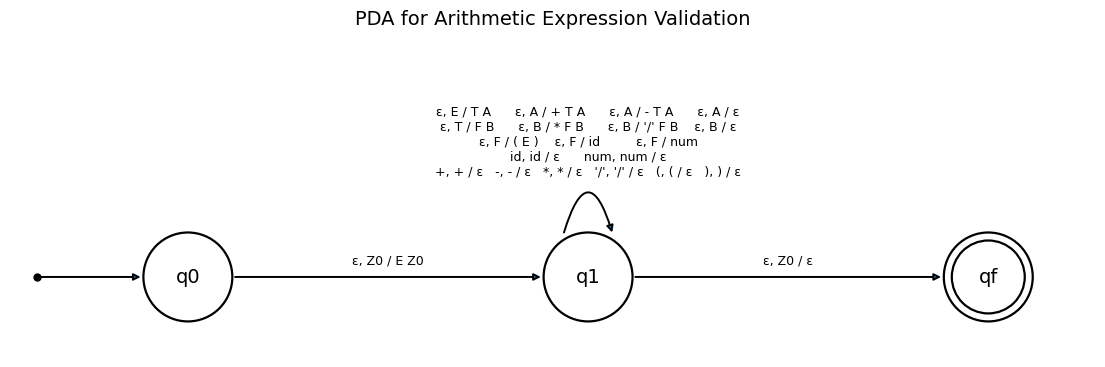

In [48]:
# PDA State Diagram for Arithmetic Expression Validation
# (uses draw_pda() from cell 4; the division symbol is written '/' to avoid confusion with the / separator)

draw_pda(
    "PDA for Arithmetic Expression Validation",
    nodes={"q0": (2.0, False), "q1": (6.5, False), "qf": (11.0, True)},
    edges=[
        ("q0", "q1", "ε, Z0 / E Z0"),
        ("q1", "q1",
         "ε, E / T A      ε, A / + T A      ε, A / - T A      ε, A / ε\n"
         "ε, T / F B      ε, B / * F B      ε, B / '/' F B    ε, B / ε\n"
         "ε, F / ( E )    ε, F / id         ε, F / num\n"
         "id, id / ε      num, num / ε\n"
         "+, + / ε   -, - / ε   *, * / ε   '/', '/' / ε   (, ( / ε   ), ) / ε"),
        ("q1", "qf", "ε, Z0 / ε"),
    ],
    width=14, height=6
)

In [27]:
def tokenize(expression):
    pattern = r'\d+(?:\.\d+)?|[a-zA-Z_]\w*|[()+\-*/]'
    tokens = re.findall(pattern, expression)

    if "".join(tokens) != re.sub(r'\s+', '', expression):
        return None

    return tokens


def validate_expression(expression):
    tokens = tokenize(expression)

    if not tokens:
        return False

    position = 0

    def parse_expression():
        nonlocal position

        if not parse_term():
            return False

        while position < len(tokens) and tokens[position] in ("+", "-"):
            position += 1

            if not parse_term():
                return False

        return True

    def parse_term():
        nonlocal position

        if not parse_factor():
            return False

        while position < len(tokens) and tokens[position] in ("*", "/"):
            position += 1

            if not parse_factor():
                return False

        return True

    def parse_factor():
        nonlocal position

        if position >= len(tokens):
            return False

        token = tokens[position]

        if token == "(":
            position += 1

            if not parse_expression():
                return False

            if position >= len(tokens) or tokens[position] != ")":
                return False

            position += 1
            return True

        if re.fullmatch(r'\d+(?:\.\d+)?|[a-zA-Z_]\w*', token):
            position += 1
            return True

        return False

    return parse_expression() and position == len(tokens)


print("Arithmetic Expression Validator is ready")

Arithmetic Expression Validator is ready


In [42]:
arithmetic_test_cases = [
    "a+b",
    "a+b*c",
    "(a+b)*c",
    "10+20/5",
    "x-y*z",
    "12.5+3",
    "(a+b)",
    "(a+b",
    "a++b",
    "*a+b",
    "a/",
    "a+b)",
    "2(3+4)",
    ""
]

arithmetic_results = []

for expression in arithmetic_test_cases:
    result = validate_expression(expression)

    arithmetic_results.append([
        expression if expression else "ε",
        "Accepted" if result else "Rejected"
    ])

arithmetic_result_table = pd.DataFrame(
    arithmetic_results,
    columns=["Arithmetic Expression", "PDA Validation Result"]
)

display(arithmetic_result_table)

,Arithmetic Expression,PDA Validation Result
0,a+b,Accepted
1,a+b*c,Accepted
2,(a+b)*c,Accepted
3,10+20/5,Accepted
4,x-y*z,Accepted
5,12.5+3,Accepted
6,(a+b),Accepted
7,(a+b,Rejected
8,a++b,Rejected
9,*a+b,Rejected


In [29]:
successful_derivation = [
    ["E", "Start"],
    ["T A", "E → T A"],
    ["F B A", "T → F B"],
    ["id B A", "F → id"],
    ["id A", "B → ε"],
    ["id + T A", "A → + T A"],
    ["id + F B A", "T → F B"],
    ["id + id B A", "F → id"],
    ["id + id A", "B → ε"],
    ["id + id", "A → ε"]
]

derivation_table = pd.DataFrame(
    successful_derivation,
    columns=["Derivation", "Production Applied"]
)

display(derivation_table)

,Derivation,Production Applied
0,E,Start
1,T A,E → T A
2,F B A,T → F B
3,id B A,F → id
4,id A,B → ε
5,id + T A,A → + T A
6,id + F B A,T → F B
7,id + id B A,F → id
8,id + id A,B → ε
9,id + id,A → ε


In [30]:
failed_cases = [
    ["a++b", "Two consecutive operators"],
    ["a+", "Missing operand"],
    ["*a+b", "Expression starts with an operator"],
    ["(a+b", "Missing closing bracket"],
    ["a+b)", "Extra closing bracket"],
    ["a**b", "Invalid operator sequence"]
]

failed_table = pd.DataFrame(
    failed_cases,
    columns=["Input Expression", "Reason for Rejection"]
)

display(failed_table)

,Input Expression,Reason for Rejection
0,a++b,Two consecutive operators
1,a+,Missing operand
2,*a+b,Expression starts with an operator
3,(a+b,Missing closing bracket
4,a+b),Extra closing bracket
5,a**b,Invalid operator sequence


In [31]:
ambiguity_table = pd.DataFrame({
    "Expression": [
        "a+b*c",
        "a-b-c",
        "(a+b)*c"
    ],
    "Grammar Property": [
        "Multiplication has higher precedence than addition",
        "Subtraction is left associative",
        "Parentheses determine grouping"
    ],
    "Result": [
        "Unambiguous",
        "Unambiguous",
        "Unambiguous"
    ]
})

display(ambiguity_table)

,Expression,Grammar Property,Result
0,a+b*c,Multiplication has higher precedence than addi...,Unambiguous
1,a-b-c,Subtraction is left associative,Unambiguous
2,(a+b)*c,Parentheses determine grouping,Unambiguous


In [43]:
total = len(arithmetic_test_cases)

accepted = sum(
    validate_expression(x)
    for x in arithmetic_test_cases
)

rejected = total - accepted

arithmetic_summary = pd.DataFrame({
    "Category": ["Total Test Cases", "Accepted", "Rejected"],
    "Count": [total, accepted, rejected]
})

display(arithmetic_summary)

print("Arithmetic Expression Testing Completed Successfully")

,Category,Count
0,Total Test Cases,14
1,Accepted,7
2,Rejected,7


Arithmetic Expression Testing Completed Successfully


In [33]:
palindrome_rules = {
    "S": ["a S a", "b S b", "a", "b", "ε"]
}

palindrome_cfg_table = pd.DataFrame(
    [(key, " | ".join(value))
     for key, value in palindrome_rules.items()],
    columns=["Non-Terminal", "Production Rules"]
)

display(palindrome_cfg_table)

,Non-Terminal,Production Rules
0,S,a S a | b S b | a | b | ε


In [49]:
# PDA transitions for the palindrome checker
# X stands for any stack symbol (Z0, a or b); the simulator in cell 27 expands it.

palindrome_transitions = [
    ["q0", "a", "X", "a X", "q0"],   # read a, push a
    ["q0", "b", "X", "b X", "q0"],   # read b, push b
    ["q0", "ε", "X", "X",   "q1"],   # guess the middle (even length)
    ["q0", "a", "X", "X",   "q1"],   # read the middle a (odd length), push nothing
    ["q0", "b", "X", "X",   "q1"],   # read the middle b (odd length), push nothing
    ["q1", "a", "a", "ε",   "q1"],   # match a, pop a
    ["q1", "b", "b", "ε",   "q1"],   # match b, pop b
    ["q1", "ε", "Z0", "ε",  "qf"]    # input finished and only Z0 left: accept
]

palindrome_pda_table = pd.DataFrame(
    palindrome_transitions,
    columns=[
        "Current State", "Input",
        "Stack Top", "Stack Replacement", "Next State"
    ]
)

display(palindrome_pda_table)

,Current State,Input,Stack Top,Stack Replacement,Next State
0,q0,a,X,a X,q0
1,q0,b,X,b X,q0
2,q0,ε,X,X,q1
3,q0,a,X,X,q1
4,q0,b,X,X,q1
5,q1,a,a,ε,q1
6,q1,b,b,ε,q1
7,q1,ε,Z0,ε,qf


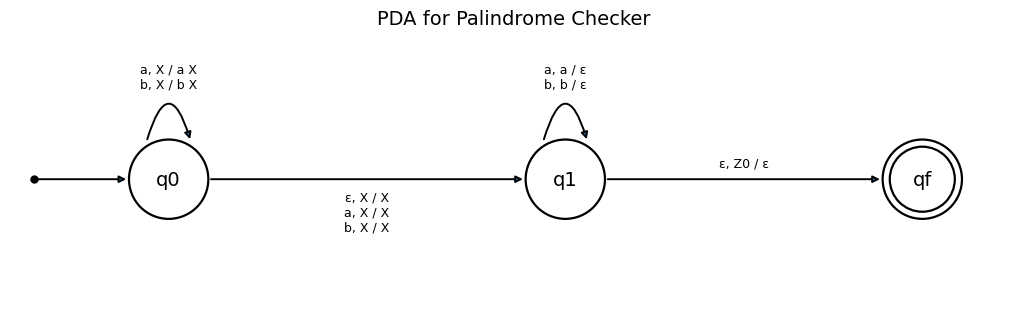

In [50]:
# PDA State Diagram for Palindrome Checker
# (uses draw_pda() from cell 4)

draw_pda(
    "PDA for Palindrome Checker",
    nodes={"q0": (2.0, False), "q1": (7.0, False), "qf": (11.5, True)},
    edges=[
        ("q0", "q0", "a, X / a X\nb, X / b X"),
        ("q0", "q1", "ε, X / X\na, X / X\nb, X / X", "below"),
        ("q1", "q1", "a, a / ε\nb, b / ε"),
        ("q1", "qf", "ε, Z0 / ε"),
    ],
    width=13, height=5.5
)

In [36]:
def validate_palindrome(string):
    if not all(char in "ab" for char in string):
        return False

    return string == string[::-1]


print("Palindrome Checker is ready")

Palindrome Checker is ready


In [37]:
palindrome_test_cases = [
    "aba",
    "abba",
    "a",
    "b",
    "aa",
    "baab",
    "bab",
    "aabbaa",
    "",
    "abab",
    "aabb",
    "abb",
    "baa",
    "abc"
]

palindrome_results = []

for string in palindrome_test_cases:
    result = validate_palindrome(string)

    palindrome_results.append([
        string if string else "ε",
        "Accepted" if result else "Rejected"
    ])

palindrome_result_table = pd.DataFrame(
    palindrome_results,
    columns=["Input String", "PDA Validation Result"]
)

display(palindrome_result_table)

,Input String,PDA Validation Result
0,aba,Accepted
1,abba,Accepted
2,a,Accepted
3,b,Accepted
4,aa,Accepted
5,baab,Accepted
6,bab,Accepted
7,aabbaa,Accepted
8,ε,Accepted
9,abab,Rejected


In [38]:
successful_derivation = [
    ["S", "Start"],
    ["a S a", "Apply S → a S a"],
    ["a b S b a", "Apply S → b S b"],
    ["a b b a", "Apply S → ε"],
    ["abba", "Remove ε"]
]

derivation_table = pd.DataFrame(
    successful_derivation,
    columns=["Derivation", "Production Applied"]
)

display(derivation_table)

,Derivation,Production Applied
0,S,Start
1,a S a,Apply S → a S a
2,a b S b a,Apply S → b S b
3,a b b a,Apply S → ε
4,abba,Remove ε


In [39]:
failed_cases = [
    ["abab", "First and last symbols do not match"],
    ["aabb", "Not a palindrome"],
    ["abb", "Not a palindrome"],
    ["baa", "Not a palindrome"],
    ["abc", "Invalid input symbol"]
]

failed_table = pd.DataFrame(
    failed_cases,
    columns=["Input String", "Reason for Rejection"]
)

display(failed_table)

,Input String,Reason for Rejection
0,abab,First and last symbols do not match
1,aabb,Not a palindrome
2,abb,Not a palindrome
3,baa,Not a palindrome
4,abc,Invalid input symbol


In [40]:
total = len(palindrome_test_cases)

accepted = sum(
    validate_palindrome(x)
    for x in palindrome_test_cases
)

rejected = total - accepted

palindrome_summary = pd.DataFrame({
    "Category": ["Total Test Cases", "Accepted", "Rejected"],
    "Count": [total, accepted, rejected]
})

display(palindrome_summary)

print("Palindrome Testing Completed Successfully")

,Category,Count
0,Total Test Cases,14
1,Accepted,9
2,Rejected,5


Palindrome Testing Completed Successfully


In [51]:
# PDA SIMULATOR
# Runs the PDA transition tables from cells 3, 11 and 20 on the test strings.
# Each table row is [state, input, stack top, stack replacement, next state].
# The stack is a tuple with the top symbol first, and "ε" means "nothing".

from collections import deque

def parse_rows(rows, stack_symbols=None):
    """Convert table rows to tuples; expand the wildcard X over stack_symbols."""
    parsed = []
    for state, read, top, push, nxt in rows:
        tops = stack_symbols if (top == "X" and stack_symbols) else [top]
        for t in tops:
            symbols = [] if push == "ε" else [t if s == "X" else s for s in push.split()]
            parsed.append((state, read, t, tuple(symbols), nxt))
    return parsed


def run_pda(rows, tokens, stack_symbols=None, start="q0", final="qf", bottom="Z0"):
    """Nondeterministic PDA simulation (breadth-first search over configurations).
    Accepts when all input is read, the machine is in qf and the stack is empty."""
    moves = parse_rows(rows, stack_symbols)
    n = len(tokens)
    begin = (start, 0, (bottom,))
    parent = {begin: None}
    queue = deque([begin])

    while queue:
        config = queue.popleft()
        state, pos, stack = config

        if state == final and pos == n and not stack:
            path = []
            while config is not None:
                path.append(config)
                config = parent[config]
            return True, path[::-1]

        if not stack or len(stack) > 4 * n + 10:
            continue

        for s, read, top, push, nxt in moves:
            if s != state or top != stack[0]:
                continue
            if read == "ε":
                new_pos = pos
            elif pos < n and tokens[pos] == read:
                new_pos = pos + 1
            else:
                continue
            new_config = (nxt, new_pos, push + stack[1:])
            if new_config not in parent:
                parent[new_config] = config
                queue.append(new_config)

    return False, []


def show_run(name, rows, tokens, stack_symbols=None):
    accepted, path = run_pda(rows, tokens, stack_symbols)
    print(f"\n{name}: input = {' '.join(tokens) if tokens else 'ε'}  ->",
          "ACCEPTED" if accepted else "REJECTED")
    for state, pos, stack in path:
        remaining = " ".join(tokens[pos:]) or "ε"
        print(f"  ({state}, {remaining}, {' '.join(stack) or 'ε'})")


def arithmetic_tokens(expression):
    """Turn an expression into PDA input symbols: numbers -> num, names -> id."""
    tokens = tokenize(expression)
    if tokens is None:
        return None
    return ["num" if t[0].isdigit() else "id" if (t[0].isalpha() or t[0] == "_") else t
            for t in tokens]


# 1. Balanced parentheses
paren_results = []
for s in test_cases:
    ok, _ = run_pda(pda_transitions, list(s))
    paren_results.append(ok == validate_parentheses(s))

# 2. Arithmetic expressions
arith_results = []
for s in arithmetic_test_cases:
    tokens = arithmetic_tokens(s)
    ok = False if tokens is None else run_pda(arithmetic_transitions, tokens)[0]
    arith_results.append(ok == validate_expression(s))

# 3. Palindromes
pal_results = []
for s in palindrome_test_cases:
    ok, _ = run_pda(palindrome_transitions, list(s), stack_symbols=["Z0", "a", "b"])
    pal_results.append(ok == validate_palindrome(s))

print("PDA simulation agrees with the Python validators on every test case:")
print("  Balanced parentheses :", all(paren_results), f"({len(paren_results)} cases)")
print("  Arithmetic           :", all(arith_results), f"({len(arith_results)} cases)")
print("  Palindromes          :", all(pal_results),   f"({len(pal_results)} cases)")

# Example runs (state, remaining input, stack)
show_run("Balanced parentheses", pda_transitions, list("()"))
show_run("Arithmetic", arithmetic_transitions, arithmetic_tokens("a+b"))
show_run("Palindrome", palindrome_transitions, list("aba"), stack_symbols=["Z0", "a", "b"])

PDA simulation agrees with the Python validators on every test case:
  Balanced parentheses : True (11 cases)
  Arithmetic           : True (14 cases)
  Palindromes          : True (14 cases)

Balanced parentheses: input = ( )  -> ACCEPTED
  (q0, ( ), Z0)
  (q1, ( ), S Z0)
  (q1, ( ), ( S ) S Z0)
  (q1, ), S ) S Z0)
  (q1, ), ) S Z0)
  (q1, ε, S Z0)
  (q1, ε, Z0)
  (qf, ε, ε)

Arithmetic: input = id + id  -> ACCEPTED
  (q0, id + id, Z0)
  (q1, id + id, E Z0)
  (q1, id + id, T A Z0)
  (q1, id + id, F B A Z0)
  (q1, id + id, id B A Z0)
  (q1, + id, B A Z0)
  (q1, + id, A Z0)
  (q1, + id, + T A Z0)
  (q1, id, T A Z0)
  (q1, id, F B A Z0)
  (q1, id, id B A Z0)
  (q1, ε, B A Z0)
  (q1, ε, A Z0)
  (q1, ε, Z0)
  (qf, ε, ε)

Palindrome: input = a b a  -> ACCEPTED
  (q0, a b a, Z0)
  (q0, b a, a Z0)
  (q1, a, a Z0)
  (q1, ε, Z0)
  (qf, ε, ε)
